# Practical 09 – K-Means Clustering with the Elbow Method

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


In [2]:
raw = load_iris(as_frame=True)
X = raw.data
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
xy = pca.fit_transform(scaled)


In [3]:
def plot_clusters(labels, title, centers=None):
    plt.figure(figsize=(8, 5))
    plt.scatter(xy[:, 0], xy[:, 1], c=labels, cmap='viridis', s=40)
    if centers is not None:
        pc = pca.transform(centers)
        plt.scatter(pc[:, 0], pc[:, 1], marker='X', s=200, c='red', label='Centroids')
        plt.legend()
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title(title)
    plt.show()


In [7]:
ks = range(1, 11)
inertias = []
for k in ks:
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled).inertia_)


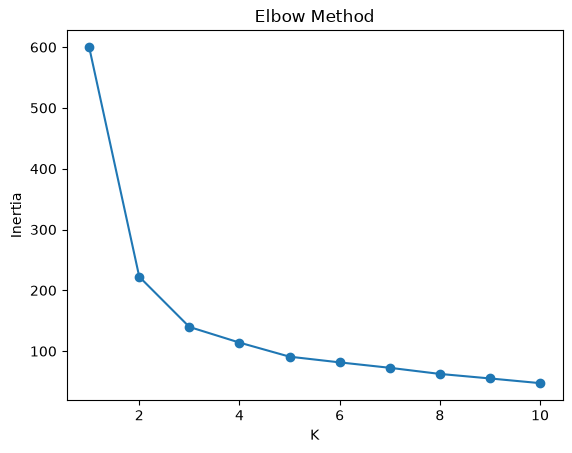

In [5]:
plt.plot(list(ks), inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(scaled)


Silhouette: 0.45994823920518635 Inertia: 139.82049635974982


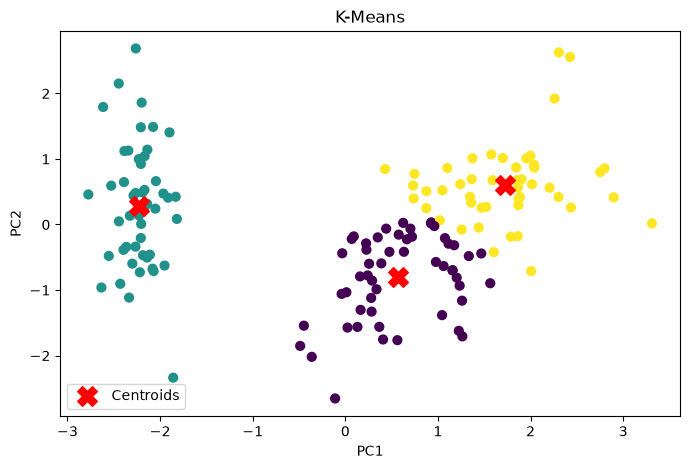

In [6]:
print('Silhouette:', silhouette_score(scaled, labels), 'Inertia:', model.inertia_)
plot_clusters(labels, 'K-Means', model.cluster_centers_)
